# DÉCLIC · Axe 7 (O08) : préparation des données, étape par étape

Ce notebook montre **comment les historiques SingPAD (chant) et Yousician (ukulélé) deviennent les
entrées du GRU**. Il appelle exactement les fonctions utilisées pour l’entraînement, dans
`axis7/cloud_training.py` : rien n’est réécrit ici.

- Il lit les caches préparés `runtime/musical-demo/*-prepared.json.gz` (données sous licence, privées,
  jamais publiées dans le dépôt).
- Les sorties ne montrent que des **comptes, des formes et des vérifications** : aucun identifiant
  d’élève, aucune ligne individuelle.

Plan : 1) les caches et leur empreinte · 2) le bug des dates et sa correction · 3) le regroupement
par moment réel · 4) l’encodage causal · 5) le découpage par élève · 6) le vocabulaire des exercices
· 7) les fenêtres données au GRU · 8) Yousician · 9) résumé.

In [1]:
import gzip, json, sys
from collections import Counter
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / 'axis7').is_dir():
    if ROOT.parent == ROOT:
        raise SystemExit('Lancer ce notebook depuis le dépôt DÉCLIC.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
from axis7 import cloud_training as ct

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3, 'font.size': 10})
BLUE, GOLD = '#1F4A72', '#A27C12'
CACHE = ROOT / 'runtime/musical-demo'
data = {s: json.load(gzip.open(CACHE / f'{s}-prepared.json.gz', 'rt', encoding='utf-8')) for s in ('singpad', 'yousician')}
for s, d in data.items():
    print(f"{s:9}  format {d['version']} · prétraitement {d['preprocessing']} · "
          f"{len(d['learners'])} élèves · archive source sha256 {d['sha256'][:16]}…")

singpad    format musical-cloud-v2 · prétraitement singpad-datetime-v2 · 1042 élèves · archive source sha256 9e87e3ccb4bbc6e9…
yousician  format musical-cloud-v2 · prétraitement yousician-active-day-v1 · 999 élèves · archive source sha256 9e4b6fe3d11381de…


## 1. Les caches et leur empreinte

`prepare()` lit l’archive d’origine, la transforme, puis écrit un cache. Le cache garde l’empreinte
SHA-256 de l’archive et le nom du prétraitement : s’ils ne correspondent pas, il est refait. Un modèle
entraîné avec l’ancien prétraitement SingPAD (dates fausses) est refusé par le registre.

Ce que la préparation a compté et écarté, tel qu’enregistré dans le cache :

In [2]:
a = data['singpad']['audit']
print('SingPAD')
print(f"  enregistrements lus           : {a['recordings']:,}")
print(f"  doublons exacts écartés       : {a['exact_duplicates_excluded']}")
print(f"  notes notées (juste/faux)     : {a['note_labels']:,}")
print(f"  élèves avec un seul moment    : {a['single_group_learners_excluded']} (écartés : rien à prévoir)")
print(f"  fuseau horaire                : {a['timezone']}")
y = data['yousician']['audit']
print('Yousician')
for k in ('raw_rows', 'exact_duplicates_excluded', 'practice_rows_excluded', 'conflicting_groups_excluded', 'single_group_learners_excluded'):
    print(f"  {k:32}: {y[k]:,}")
print(f"  limite documentée              : {y['limitation']}")

SingPAD
  enregistrements lus           : 19,892
  doublons exacts écartés       : 0
  notes notées (juste/faux)     : 1,081,876
  élèves avec un seul moment    : 32 (écartés : rien à prévoir)
  fuseau horaire                : source local time, unspecified; never converted to UTC
Yousician
  raw_rows                        : 415,461
  exact_duplicates_excluded       : 478
  practice_rows_excluded          : 31,275
  conflicting_groups_excluded     : 23,955
  single_group_learners_excluded  : 1
  limite documentée              : no unique attempt ID; ambiguous repeated counters excluded, not guessed


## 2. Le bug des dates SingPAD et sa correction

SingPAD écrit ses dates sans zéros : `2023/8/7 9:05`. La première version triait ces dates **comme du
texte** : `"2023/8/10"` passe alors avant `"2023/8/7"` (le caractère `1` est avant `7`). Le modèle
lisait donc certains parcours dans le désordre, et voyait parfois le futur avant le passé.

`parse_singpad_time` lit chaque champ comme un nombre et refuse les formats douteux :

In [3]:
exemples = ['2023/8/7 9:05', '2023/8/10 18:30', '2023/8/9 7:00']
print('tri comme du texte :', sorted(exemples))
print('tri par la vraie date :', sorted(exemples, key=ct.parse_singpad_time))
for douteux in ['2023/13/1 10:00', '07/08/2023 10:00', '2023/8/7']:
    try:
        ct.parse_singpad_time(douteux)
    except ValueError as e:
        print(f'refusé : {douteux!r:22} → {e}')

tri comme du texte : ['2023/8/10 18:30', '2023/8/7 9:05', '2023/8/9 7:00']
tri par la vraie date : ['2023/8/7 9:05', '2023/8/9 7:00', '2023/8/10 18:30']
refusé : '2023/13/1 10:00'      → Invalid SingPAD calendar timestamp
refusé : '07/08/2023 10:00'     → Unsupported SingPAD local timestamp format
refusé : '2023/8/7'             → Unsupported SingPAD local timestamp format


Combien de parcours réels étaient touchés ? Chaque moment du cache garde sa date d’origine
(`original_timestamps`). On retrie les moments de chaque élève **comme l’ancienne version** (texte) et
on compte les paires voisines dans le mauvais ordre :

In [4]:
touches = inversions = 0
for rows in data['singpad']['learners'].values():
    texte = sorted(rows, key=lambda r: min(r['original_timestamps']))
    vraies = [ct.parse_singpad_time(min(r['original_timestamps'])) for r in texte]
    n = sum(a > b for a, b in zip(vraies, vraies[1:]))
    inversions += n; touches += n > 0
print(f'ancien tri (texte) : {touches} parcours sur {len(data["singpad"]["learners"])} dans le désordre, {inversions} inversions')
print('après correction   :', ct.chronological_audit(data['singpad']['learners']))

ancien tri (texte) : 340 parcours sur 1042 dans le désordre, 478 inversions
après correction   : {'learners': 1042, 'time_groups': 18328, 'chronological_inversions': 0, 'duplicate_time_groups': 0}


## 3. Regrouper par moment réel

Des enregistrements faits **à la même minute** forment un seul moment (un « groupe ») : on ne peut pas
savoir lequel est venu avant l’autre, et cent notes d’un seul enregistrement ne sont pas cent séances.
Pour chaque moment et chaque concept musical *k*, on garde **n** notes observées et **s** réussies.

270 concepts musicaux (codes de la source, gardés tels quels)
18,328 moments · 836 réunissent plusieurs enregistrements de la même minute
moments par élève : médiane 15, de 2 à 30
notes par moment  : médiane 52


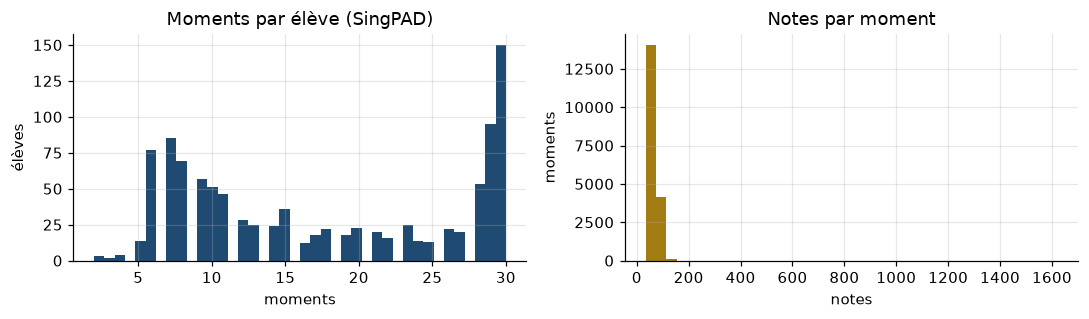

In [5]:
L = data['singpad']['learners']
K = max(o[0] for rs in L.values() for r in rs for o in r['obs']) + 1
moments = [len(rs) for rs in L.values()]
notes = [len(r['obs']) for rs in L.values() for r in rs]
regroupes = sum(r['recording_count'] > 1 for rs in L.values() for r in rs)
print(f'{K} concepts musicaux (codes de la source, gardés tels quels)')
print(f'{sum(moments):,} moments · {regroupes:,} réunissent plusieurs enregistrements de la même minute')
print(f'moments par élève : médiane {int(np.median(moments))}, de {min(moments)} à {max(moments)}')
print(f'notes par moment  : médiane {int(np.median(notes))}')
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(moments, bins=40, color=BLUE); ax[0].set(title='Moments par élève (SingPAD)', xlabel='moments', ylabel='élèves')
ax[1].hist(notes, bins=40, color=GOLD); ax[1].set(title='Notes par moment', xlabel='notes', ylabel='moments')
plt.tight_layout(); plt.show()

## 4. L’encodage : seulement le passé

`encode()` transforme le parcours d’un élève en tableaux. Au moment *t*, l’entrée **x[t]** (taille 4K) contient :

| colonnes | contenu |
|---|---|
| 0 … 2K | échecs et réussites du moment **précédent**, par concept (en proportion) |
| 2K … 3K | log(1 + réussites cumulées **avant** t) |
| 3K … 4K | log(1 + échecs cumulés **avant** t) |

plus l’exercice précédent et l’exercice demandé à *t*. La cible **y[t]** est la part de réussites à *t*,
pondérée par **w[t]** = nombre de notes. Le tout premier moment n’est pas noté (w = 0) : il n’y a pas de passé.

In [6]:
eleve = max(L.values(), key=len)                    # le parcours le plus long, sans afficher qui
items = {v: i + 1 for i, v in enumerate(sorted({r['exercise'] for rs in L.values() for r in rs}))}
x, prev_item, item, diff, y_, w = ct.encode(eleve, K, items)
print('x', x.shape, '· y', y_.shape, '· w', w.shape, '· exercices', item.shape)
print('premier moment noté ?', bool(w[0].sum()), '· moments notés :', int((w.sum(1) > 0).sum()))

# Preuve de causalité : on change le résultat du DERNIER moment ; les entrées jusqu’à lui ne bougent pas.
modifie = json.loads(json.dumps(eleve))
for o in modifie[-1]['obs']:
    o[1] = 1 - o[1]
x2 = ct.encode(modifie, K, items)[0]
print('entrées identiques jusqu’au dernier moment inclus :', np.array_equal(x, x2))

x (30, 1080) · y (30, 270) · w (30, 270) · exercices (30,)
premier moment noté ? False · moments notés : 29
entrées identiques jusqu’au dernier moment inclus : True


## 5. Le découpage par élève

`split_learners()` mélange les **élèves** (pas les notes) avec une graine fixe : 70 % entraînement,
15 % validation, 15 % test. Un élève de test n’a jamais été vu par le modèle. On le refait avec trois
graines pour ne pas dépendre d’un tirage. `public_split_provenance()` refuse tout recouvrement et ne
publie que des comptes et des empreintes.

In [7]:
for seed in (42, 17, 83):
    splits = ct.split_learners(L, seed)
    pub = ct.public_split_provenance(splits)
    print(f"graine {seed} : " + ' · '.join(f"{k} {v['count']} élèves (sha256 {v['sha256'][:10]}…)" for k, v in pub.items()))

graine 42 : train 729 élèves (sha256 7c762850c6…) · validation 156 élèves (sha256 561750436d…) · test 157 élèves (sha256 f354dc9bfb…)
graine 17 : train 729 élèves (sha256 03998c5fce…) · validation 156 élèves (sha256 323e7c277d…) · test 157 élèves (sha256 6efe23f046…)
graine 83 : train 729 élèves (sha256 a565611506…) · validation 156 élèves (sha256 5ddda00c84…) · test 157 élèves (sha256 6330cd8b5a…)


## 6. Le vocabulaire des exercices : appris sur l’entraînement seulement

`fit_items()` numérote les exercices vus **dans le groupe d’entraînement**. Un exercice qui n’apparaît
qu’en test reçoit le code 0 (« inconnu ») : le modèle n’apprend rien des exercices de test.

In [8]:
splits = ct.split_learners(L, 42)
vocab = ct.fit_items(L, splits['train'])
test_ex = {r['exercise'] for p in splits['test'] for r in L[p]}
print(f'{len(vocab)} exercices appris · {len(test_ex)} exercices en test, dont {len(test_ex - set(vocab))} inconnus (code 0)')

88 exercices appris · 58 exercices en test, dont 6 inconnus (code 0)


## 7. Les fenêtres données au GRU

`windows()` coupe chaque parcours en morceaux de 64 moments au plus, sans recouvrement des cibles. Les
cumuls gardent tout le passé ; seul le premier moment d’un morceau sert d’échauffement (non noté).

In [9]:
for name, ids in splits.items():
    s = ct.windows(L, ids, K, vocab, context=64)
    print(f"{name:10} : {len(s):5} fenêtres · {sum(int(w.sum()) for *_, w in s):,} notes à prévoir")

train      :   729 fenêtres · 709,328 notes à prévoir
validation :   156 fenêtres · 132,333 notes à prévoir
test       :   157 fenêtres · 148,076 notes à prévoir


## 8. Yousician : une autre cible, gardée à part

Yousician n’a pas de concepts par note : la cible est la **part de notes et d’accords réussis au prochain
jour actif** (un score entre 0 et 1, chaque jour pesant autant). Les compteurs ambigus sont écartés, pas
devinés. Les deux bases ne sont jamais mélangées.

999 élèves · 12,596 jours actifs · médiane 12 jours par élève
score du jour : moyenne 0.81, médiane 0.84


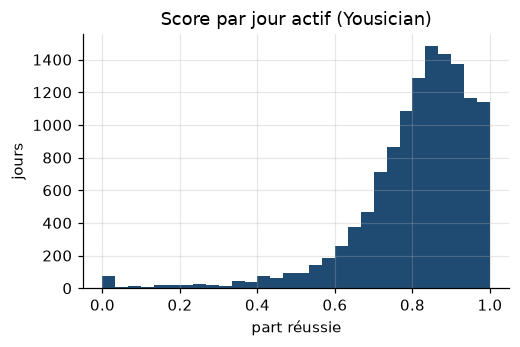

In [10]:
Y = data['yousician']['learners']
jours = [len(rs) for rs in Y.values()]
scores = [o[1] for rs in Y.values() for r in rs for o in r['obs']]
print(f'{len(Y)} élèves · {sum(jours):,} jours actifs · médiane {int(np.median(jours))} jours par élève')
print(f'score du jour : moyenne {np.mean(scores):.2f}, médiane {np.median(scores):.2f}')
plt.figure(figsize=(5, 3)); plt.hist(scores, bins=30, color=BLUE)
plt.title('Score par jour actif (Yousician)'); plt.xlabel('part réussie'); plt.ylabel('jours'); plt.show()

## 9. Résumé

1. **Dates** : lues champ par champ, formats douteux refusés ; l’ancien tri texte mettait des centaines
   de parcours dans le désordre, la version actuelle n’a aucune inversion.
2. **Moments** : les enregistrements de la même minute forment un seul moment ; n notes et s réussites par concept.
3. **Entrées** : uniquement le passé (moment précédent + cumuls log), causalité vérifiée ci-dessus.
4. **Élèves séparés** entre entraînement, validation et test, avec trois graines.
5. **Vocabulaire** appris sur l’entraînement seulement.
6. **Chaque base garde sa cible** ; rien n’est inventé ni mélangé.

Code : `axis7/cloud_training.py` (`parse_singpad_time`, `chronological_audit`, `load_singpad`,
`load_yousician`, `prepare`, `split_learners`, `fit_items`, `encode`, `windows`). Justification écrite :
`docs/PHASE6_SCIENCE_FR.md`.